In [1]:
!pip install -q gensim

from gensim.models import Word2Vec

# Sample document corpus
corpus = [
    ["machine", "learning", "is", "fun"],
    ["deep", "learning", "uses", "neural", "networks"],
    ["deep", "learning"]
]

# Train the Word2Vec model
model = Word2Vec(
    sentences=corpus,
    vector_size=50,   # Size of word embeddings
    window=2,         # Context window size
    min_count=1,      # Include all words
    workers=1,
    seed=42           # Same output every run
)

# Print the embedding vector for a word
print("Embedding for 'learning':")
print(model.wv["learning"])

# Find similar words
print("\nWords similar to 'learning':")
print(model.wv.most_similar("learning"))

Embedding for 'learning':
[-1.6429963e-02  1.0958240e-02  6.1828587e-03 -2.4448633e-03
 -2.6793908e-03  1.4343915e-02 -1.6562175e-02  7.8947209e-03
 -1.1941221e-02 -1.6232908e-02  1.0591579e-03  1.9024892e-02
  9.4300937e-03  1.0445587e-02  8.6990902e-03  1.1442571e-02
  5.2906276e-04 -1.4875455e-02  1.3589928e-02 -1.9845630e-03
  1.4076233e-05 -5.1680803e-03 -1.2698016e-02  1.7070599e-02
  1.1262698e-02  5.7546045e-03 -3.9034272e-03  1.2910464e-02
  1.8171645e-03 -2.2634340e-03 -1.9816183e-03 -1.0910451e-02
 -1.6314564e-02  2.1833896e-03  1.5515592e-02 -1.7447311e-02
  1.4331651e-02  1.3105244e-02 -8.9296130e-03  5.2665756e-03
 -1.3390839e-02  1.0323508e-02  8.0209188e-03 -5.8189631e-03
 -1.7283201e-02  1.8827921e-02 -2.1725011e-03  1.5724843e-02
  7.1167587e-03  1.1135340e-02]

Words similar to 'learning':
[('is', 0.044465333223342896), ('networks', -0.013858048245310783), ('uses', -0.02738454006612301), ('fun', -0.056496165692806244), ('neural', -0.06604263186454773), ('machine', -0

In [2]:
import numpy as np
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

tf.keras.utils.set_random_seed(42)   # same output every run

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Build the Deep Neural Network
model = Sequential([
    Input(shape=(4,)),
    Dense(16, activation='relu'),
    Dense(12, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')   # 3 output classes
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model summary
model.summary()

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=1)

# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

# Predict on test data
predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)

print("\nPredicted Classes:", predicted_classes)
print("Actual Classes   :", y_test)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           204 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 415 (1.62 KB)

 Trainable params: 415 (1.62 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4917 - loss: 1.0737
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6667 - loss: 1.0141
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6833 - loss: 0.9582
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7417 - loss: 0.9005 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7583 - loss: 0.8385 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7917 - loss: 0.7751 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8000 - loss: 0.7095 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8000 - loss: 0.6465 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8083 - loss: 0.5890 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8250 - loss: 0.5378 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8417 - loss: 0.4937 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.

In [3]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

tf.keras.utils.set_random_seed(42)

# 1. Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Preprocess: reshape & normalize
x_train = x_train.reshape((-1, 28, 28, 1)).astype('float32') / 255.0
x_test = x_test.reshape((-1, 28, 28, 1)).astype('float32') / 255.0

# One-hot encode labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 3. Build CNN model
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')   # 10 classes
])

# 4. Compile
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 5. Train
model.fit(x_train, y_train, epochs=10, batch_size=64, verbose=1)

# 6. Evaluate
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {acc*100:.2f}%")

# 7. Predict first 10 samples
predictions = model.predict(x_test[:10])
print("Predicted classes:", np.argmax(predictions, axis=1))
print("Actual classes:", np.argmax(y_test[:10], axis=1))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 44s 45ms/step - accuracy: 0.9286 - loss: 0.2338
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 85s 48ms/step - accuracy: 0.9762 - loss: 0.0805
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 74s 39ms/step - accuracy: 0.9821 - loss: 0.0600
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 40s 38ms/step - accuracy: 0.9855 - loss: 0.0487
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 43s 46ms/step - accuracy: 0.9877 - loss: 0.0411
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 70s 34ms/step - accuracy: 0.9890 - loss: 0.0349
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 31s 33ms/step - accuracy: 0.9910 - loss: 0.0295
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - accuracy: 0.9913 - loss: 0.0275
Epoch 9/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - accuracy: 0.9928 - loss: 0.0230
Epoch 10/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 30s 32ms/step - accuracy: 0.9934 - loss: 0.0204
Test Accuracy: 99.16%
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
Predicte

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.2773
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1705
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1445
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1290
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1185
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 936us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


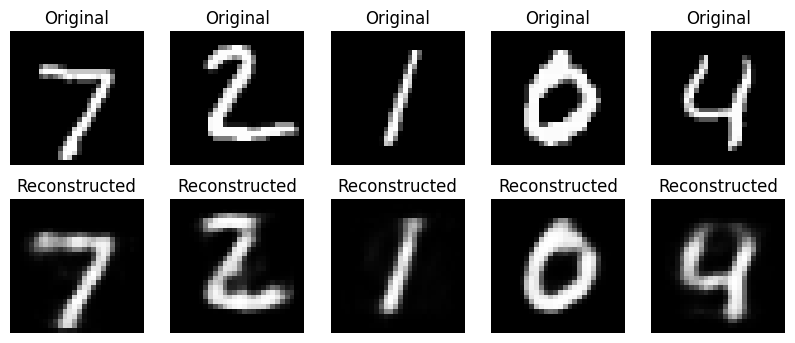

Original size: (10000, 784)
Compressed size: (10000, 32)


In [4]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

# Load dataset
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

# Normalize and flatten
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Input
input_img = layers.Input(shape=(784,))

# Encoder - compression (784 -> 32)
encoded = layers.Dense(32, activation="relu")(input_img)

# Decoder - reconstruction (32 -> 784)
decoded = layers.Dense(784, activation="sigmoid")(encoded)

# Autoencoder
model = Model(input_img, decoded)

# Compile
model.compile(optimizer="adam", loss="binary_crossentropy")

# Train
model.fit(x_train, x_train, epochs=5, batch_size=256)

# Encoder model
encoder = Model(input_img, encoded)

# Compressed images
encoded_imgs = encoder.predict(x_test)

# Reconstructed images
decoded_imgs = model.predict(x_test)

# Display original and reconstructed images
n = 5
plt.figure(figsize=(10, 4))

for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.show()

# Display sizes
print("Original size:", x_test.shape)
print("Compressed size:", encoded_imgs.shape)

In [5]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, GlobalAveragePooling1D, Dense
from tensorflow.keras.utils import pad_sequences

tf.keras.utils.set_random_seed(42)

# 1. Load IMDB dataset (Movie Reviews)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(
    num_words=10000
)

# 2. Make all reviews the same length
x_train = pad_sequences(x_train, maxlen=200)
x_test = pad_sequences(x_test, maxlen=200)

# 3. Create deep learning model
model = Sequential([
    Input(shape=(200,)),
    Embedding(10000, 32),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 4. Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 5. Train model
model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

# 6. Test model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy)

# 7. Predict first 5 reviews
predictions = model.predict(x_test[:5])

print("\nReview Classification:")

for i in range(5):
    if predictions[i][0] >= 0.5:
        result = "Positive"
    else:
        result = "Negative"

    print("Review", i + 1, ":", result)
    print("Probability:", predictions[i][0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7793 - loss: 0.4651 - val_accuracy: 0.8598 - val_loss: 0.3323
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8956 - loss: 0.2601 - val_accuracy: 0.8696 - val_loss: 0.3115
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9201 - loss: 0.2055 - val_accuracy: 0.8654 - val_loss: 0.3266
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9363 - loss: 0.1717 - val_accuracy: 0.8576 - val_loss: 0.3702
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9470 - loss: 0.1486 - val_accuracy: 0.8434 - val_loss: 0.4469
782/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8300 - loss: 0.4701
Test Accuracy: 0.8299999833106995
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step

Review Classification:
Review 1 : Positive
Probability: 0.80884224
Review 2 : Positive
Probability: 0.9994236
Review 3 : Positive
Probability: 0.9025952
Review 4 : Po

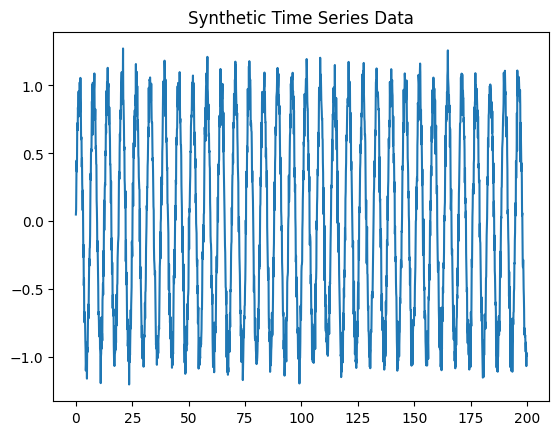

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0753 - val_loss: 0.0219
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0095 - val_loss: 0.0036
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0033 - val_loss: 0.0027
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0026 - val_loss: 0.0022
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0022 - val_loss: 0.0019
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0021 - val_loss: 0.0019
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0020 - val_loss: 0.0019


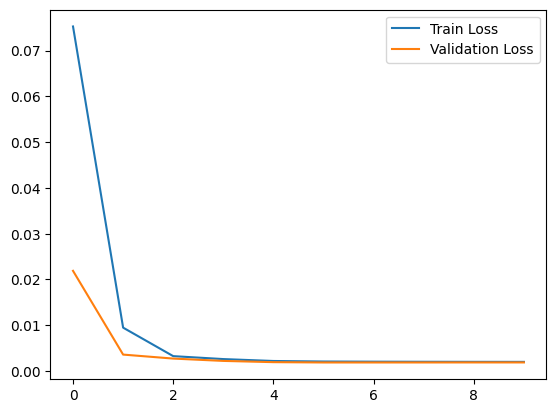

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


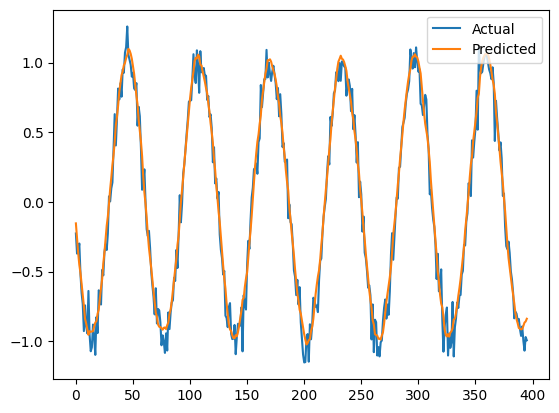

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

np.random.seed(42)
tf.keras.utils.set_random_seed(42)   # same output every run

# 1. Generate synthetic time series data
time = np.arange(0, 200, 0.1)
data = np.sin(time) + 0.1 * np.random.randn(len(time))
plt.plot(time, data)
plt.title("Synthetic Time Series Data")
plt.show()

# 2. Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(data.reshape(-1, 1))

# 3. Create sequences
def create_sequences(dataset, seq_length):
    X, y = [], []
    for i in range(len(dataset) - seq_length):
        X.append(dataset[i:i + seq_length, 0])
        y.append(dataset[i + seq_length, 0])
    return np.array(X), np.array(y)

SEQ_LEN = 20
X, y = create_sequences(data_scaled, SEQ_LEN)

# 4. Reshape for LSTM (samples, timesteps, features)
X = X.reshape((X.shape[0], X.shape[1], 1))

# 5. Train-test split
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# 6. Build LSTM model
model = Sequential([
    Input(shape=(SEQ_LEN, 1)),
    LSTM(50, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

# 7. Train model
history = model.fit(X_train, y_train, epochs=10, batch_size=32,
                    validation_data=(X_test, y_test), verbose=1)

# 8. Plot training loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

# 9. Forecast
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

# 10. Plot predictions vs actual
plt.plot(y_test_actual, label='Actual')
plt.plot(predictions, label='Predicted')
plt.legend()
plt.show()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2759s 16us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 276s 217ms/step - accuracy: 0.8209 - loss: 0.5294 - val_accuracy: 0.8515 - val_loss: 0.4314
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 281s 224ms/step - accuracy: 0.8697 - loss: 0.3793 - val_accuracy: 0.8548 - val_loss: 0.4263
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 245s 196ms/step - accuracy: 0.8864 - loss: 0.3313 - val_accuracy: 0.8574 - val_loss: 0.4229
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 253s 189ms/step - accuracy: 0.8971 - loss: 0.2944 - val_accuracy: 0.8606 - val_loss: 0.4177
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 276s 221ms/step - accuracy: 0.9098 - loss: 0.2600 - val_accuracy: 0.8633 - val_loss: 0.4079
Test Accuracy: 86.080002784729 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Actual: cat
Predicted: cat
Training Accuracy: 90.97750186920166 %
Validation Accuracy: 86.33000254631042 %


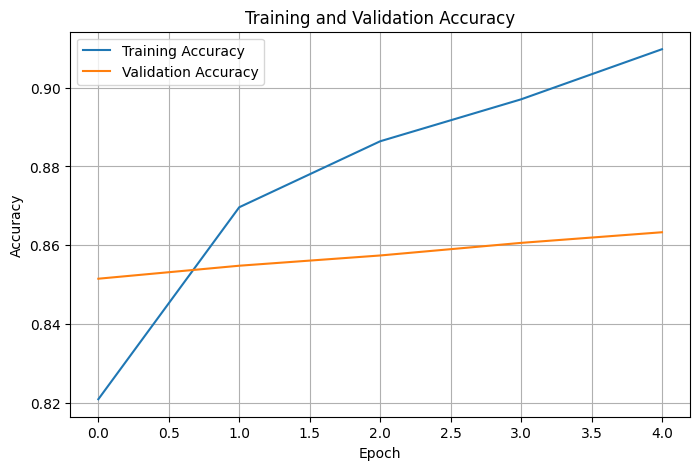

In [7]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

tf.keras.utils.set_random_seed(42)

# 1. Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Convert labels to 1D
y_train = y_train.flatten()
y_test = y_test.flatten()

# 2. Resize + preprocess images batch by batch (saves memory)
def prep(img, label):
    img = tf.image.resize(tf.cast(img, tf.float32), (96, 96))
    img = tf.keras.applications.mobilenet_v2.preprocess_input(img)
    return img, label

n_val = 10000   # last 10000 training images used for validation
train_ds = (tf.data.Dataset.from_tensor_slices((x_train[:-n_val], y_train[:-n_val]))
            .shuffle(10000).map(prep).batch(32).prefetch(tf.data.AUTOTUNE))
val_ds = (tf.data.Dataset.from_tensor_slices((x_train[-n_val:], y_train[-n_val:]))
          .map(prep).batch(32).prefetch(tf.data.AUTOTUNE))
test_ds = (tf.data.Dataset.from_tensor_slices((x_test, y_test))
           .map(prep).batch(32).prefetch(tf.data.AUTOTUNE))

# 3. Load pre-trained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pre-trained layers
base_model.trainable = False

# 4. Create model
model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# 5. Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. Train
history = model.fit(train_ds, validation_data=val_ds, epochs=5)

# 7. Test model
loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print("Test Accuracy:", test_accuracy * 100, "%")

# 8. Predict one image
classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
sample, _ = prep(x_test[:1], y_test[:1])
prediction = model.predict(sample)
predicted_class = np.argmax(prediction)

print("Actual:", classes[y_test[0]])
print("Predicted:", classes[predicted_class])

# Final training and validation accuracy
print("Training Accuracy:", history.history["accuracy"][-1] * 100, "%")
print("Validation Accuracy:", history.history["val_accuracy"][-1] * 100, "%")

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Dataset (20 positive + 20 negative reviews)
positive = [
    "I loved this movie, it was fantastic",
    "The product is excellent and very useful",
    "Amazing experience, I really enjoyed it",
    "The service was wonderful",
    "Very happy with my purchase",
    "Absolutely brilliant, I loved every minute",
    "Great quality and works perfectly",
    "The staff were friendly and helpful",
    "An amazing film with a beautiful story",
    "I am very satisfied, highly recommended",
    "Excellent value for money, I love it",
    "The food was delicious and fresh",
    "Fantastic performance, truly enjoyable",
    "Best purchase I have made, very happy",
    "Wonderful experience, great service",
    "This product is awesome and easy to use",
    "I really liked the movie, it was great",
    "Superb quality, I am impressed",
    "Delightful and amazing, I enjoyed it a lot",
    "Very good product, works well and I am happy",
]
negative = [
    "This product is terrible",
    "I hated this movie",
    "Very disappointing experience",
    "The product broke after one day",
    "Poor quality and bad service",
    "Awful film, a complete waste of time",
    "The worst purchase, I am very unhappy",
    "The staff were rude and unhelpful",
    "A boring movie with a terrible story",
    "I am very disappointed, do not buy",
    "Bad value for money, I hate it",
    "The food was cold and tasteless",
    "Horrible performance, truly disappointing",
    "Worst experience ever, awful service",
    "This product is useless and stopped working",
    "I really disliked the movie, it was bad",
    "Cheap quality, I am not impressed",
    "Dreadful and boring, I regret it",
    "Very bad product, broken and I am unhappy",
    "Terrible service and awful quality",
]

reviews = positive + negative
# Labels: 1 = Positive, 0 = Negative
labels = [1] * len(positive) + [0] * len(negative)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    reviews, labels, test_size=0.2, random_state=42, stratify=labels
)

# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(stop_words="english")
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train the model
model = LogisticRegression(C=10)
model.fit(X_train_tfidf, y_train)

# Predict test data
y_pred = model.predict(X_test_tfidf)
print("Test Accuracy:", accuracy_score(y_test, y_pred))

# Test new reviews
new_reviews = [
    "The movie was amazing and I loved it",
    "The product was awful and disappointing",
    "I am very happy with this purchase",
]

new_reviews_tfidf = vectorizer.transform(new_reviews)
predictions = model.predict(new_reviews_tfidf)

# Display results
for review, prediction in zip(new_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print("\nReview:", review)
    print("Sentiment:", sentiment)

Test Accuracy: 0.5

Review: The movie was amazing and I loved it
Sentiment: Positive

Review: The product was awful and disappointing
Sentiment: Negative

Review: I am very happy with this purchase
Sentiment: Positive
